# 01 - Roll-Rate Analysis & Target Definition
**Data:** UCI *Default of Credit Card Clients* (30,000 Taiwanese card accounts, Apr-Sep 2005) - real data.

**Scope note (honest):** the dataset is a single 6-month snapshot with no origination dates, so a true *origination-cohort vintage analysis* and a calendar *out-of-time* holdout are **not possible**. What the data does support is a real **roll-rate analysis** from 6 months of repayment status, plus a stratified train/test split.

In [1]:
import os, sys; os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None; sys.path.insert(0,'.')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
%matplotlib inline
from src.features import load, split, ST
df = load(); print(df.shape, 'default rate: %.2f%%' % (df.default.mean()*100))

(30000, 29) default rate: 22.12%


## Roll-rate matrix (month t -> t+1), pooled over 5 monthly transitions
PAY status: <=0 current, 1 = 1 month late (30 DPD), 2 = 60 DPD, >=3 = 90+ DPD.

In [2]:
state = lambda s: np.select([s<=0, s==1, s==2], [0,1,2], default=3)
cols = ['PAY_6','PAY_5','PAY_4','PAY_3','PAY_2','PAY_1']; L = ['Current','30 DPD','60 DPD','90+ DPD']
M = np.zeros((4,4))
for a,b in zip(cols[:-1], cols[1:]):
    sa, sb = state(df[a].values), state(df[b].values)
    for i in range(4):
        for j in range(4): M[i,j] += ((sa==i)&(sb==j)).sum()
R = pd.DataFrame(M/M.sum(1,keepdims=True), index=L, columns=L); display(R.round(3))
for s in L[1:]: print(f'Cure rate {s:8s} -> Current next month: {R.loc[s,"Current"]*100:5.1f}%')
cure90 = R.loc['90+ DPD','Current']; print('\n90+ DPD cure rate < 10% threshold?', cure90 < 0.10)

,Current,30 DPD,60 DPD,90+ DPD
Current,0.939,0.014,0.047,0.000
30 DPD,0.000,1.000,0.000,0.000
60 DPD,0.253,0.103,0.580,0.063
90+ DPD,0.107,0.081,0.282,0.531


Cure rate 30 DPD   -> Current next month:   0.0%
Cure rate 60 DPD   -> Current next month:  25.3%
Cure rate 90+ DPD  -> Current next month:  10.7%

90+ DPD cure rate < 10% threshold? False


## Next-month default rate by latest delinquency state

,default % (next month),count
Current,13.8,23182
30 DPD,33.9,3688
60 DPD,69.1,2667
90+ DPD,71.9,463


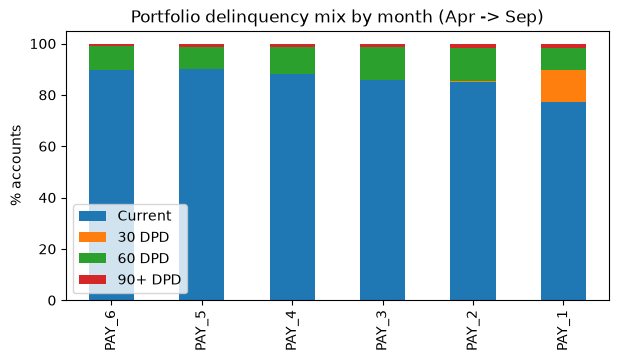

In [3]:
g = df.groupby(pd.Series(state(df.PAY_1.values), index=df.index).map(dict(enumerate(L)))).default.agg(['mean','count']).reindex(L); g['mean'] = g['mean']*100; display(g.rename(columns={'mean':'default % (next month)'}).round(1))
share = pd.DataFrame({c: pd.Series(state(df[c].values)).map(dict(enumerate(L))).value_counts(normalize=True) for c in cols}).reindex(L)*100
share.T.plot(kind='bar', stacked=True, figsize=(7,3.5), title='Portfolio delinquency mix by month (Apr -> Sep)'); plt.ylabel('% accounts'); plt.show()

## Target definition & sampling
Target = the dataset's *default payment next month* flag (1 = default). Roll rates show how sticky deep delinquency is. Sample: **stratified 70/30 split** (seed 42) preserving the 22.1% bad rate; no OOT set exists (see scope note).

In [4]:
train, test = split(df); os.makedirs('data/processed', exist_ok=True); joblib.dump((train, test), 'data/processed/split.joblib')
print(len(train), len(test), 'bad rate train %.4f / test %.4f' % (train.default.mean(), test.default.mean()))

21000 9000 bad rate train 0.2212 / test 0.2212
